In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import random
import types

from time import time

from scipy.special import comb, loggamma, lambertw
from scipy.stats import multinomial, expon

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config = config)

import os, shutil
from pathlib import Path
import json
import subprocess

import lifelines
from lifelines.utils import concordance_index
from lifelines.statistics import logrank_test

import sys
sys.path.insert(0, "../src")
from package import cure_aft
from package import gndr_utils as utils

import thetaflow as thf

E0000 00:00:1793254294.918045   27711 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793254294.923293   27711 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793254294.936176   27711 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793254294.936203   27711 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793254294.936206   27711 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793254294.936209   27711 computation_placer.cc:177] computation placer already registered. Please check linka

In this notebook, we explore the results for the AFT cure rate models assuming
\begin{align*}
    \mu &= \boldsymbol z_\mu^\top \boldsymbol \beta_\mu + \mathcal{F}(\boldsymbol x_i ; \boldsymbol \omega)\\
    \sigma &= \boldsymbol z_\sigma^\top \boldsymbol \beta_\sigma\\
    p &= \boldsymbol z_p^\top \boldsymbol \beta_p
\end{align*}

In [2]:
df_clean_train = pd.read_csv("../data/00_clean/metabric_train_data.csv")
df_clean_test = pd.read_csv("../data/00_clean/metabric_test_data.csv")

df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")

print("Train data dimension: {}".format(df_train.shape))
print("Test data dimension: {}".format(df_test.shape))

df_train.head()

Train data dimension: (1386, 183)
Test data dimension: (463, 183)


,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-5223,136.700000,1.0,-1.472877,-0.016511,0.0,0.0,0.0,0.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,MB-5576,194.000000,0.0,0.497740,-0.020040,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-6238,172.966667,1.0,1.805360,-0.886508,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-0379,119.500000,1.0,-1.000511,-0.004158,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-4708,18.700000,1.0,0.133321,-0.023570,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Lifetimes and censoring indicators
y_train = df_train["time"] / 12
delta_train = df_train["delta"]
# Data for the neural network interpreter
X_train_nn = df_train.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_train_mu = df_train.iloc[:, 3:10]
# z_train_mu.insert(0, "const", 1) # Can't have an intercept in mu since the neural net component already accounts for it
z_train_sigma = df_train.iloc[:, 5:10]
z_train_sigma.insert(0, "const", 1)
z_train_p = df_train.iloc[:, 3:10]
z_train_p.insert(0, "const", 1)

# Lifetimes and censoring indicators
y_test = df_test["time"] / 12
delta_test = df_test["delta"]
# Data for the neural network interpreter
X_test_nn = df_test.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_test_mu = df_test.iloc[:, 3:10]
# z_test_mu.insert(0, "const", 1) # Can't have an intercept in mu since the neural net component already accounts for it
z_test_sigma = df_test.iloc[:, 5:10]
z_test_sigma.insert(0, "const", 1)
z_test_p = df_test.iloc[:, 3:10]
z_test_p.insert(0, "const", 1)

In [4]:
wb_parameters, wb_loss, wb_survival_cure = cure_aft.build_cure_aft_structure2("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters, ln_loss, ln_survival_cure = cure_aft.build_cure_aft_structure2("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters, ll_loss, ll_survival_cure = cure_aft.build_cure_aft_structure2("ll", z_train_mu, z_train_sigma, z_train_p)

data_train = [z_train_mu, z_train_sigma, z_train_p, y_train, delta_train]
data_test = [z_test_mu, z_test_sigma, z_test_p, y_test, delta_test]

In [5]:
wb_model = cure_aft.train_model( wb_parameters, wb_loss, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast, X_train_nn, data_train )
wb_summary = wb_survival_cure(wb_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 87 / 15000 ]  | Avg. Train NLL:  1.83769369 | Avg. Validation NLL:  1.99671924 | Best Avg. Validation NLL:  1.89943039 | Speed:  0.0161608588  epoch/s    | Elapsed Time:  1.40599465  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 88 / 15000 ]  | Avg. Train NLL:  1.8382827 | Avg. Validation NLL:  1.99738014 | Best Avg. Validation NLL:  1.89943039 | Speed:  0.0161555279  epoch/s    | Elapsed Time:  1.42168641  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 3035 / 15000 ]  | Avg. Train NLL:  1.42212749 | Best Avg. Train NLL:  1.42212749 | Avg. Validation NLL:  1.91455317 | Speed:  0.00873788167  epoch/s    | Elapsed Time:  26.5194702  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 44.646 seconds.


In [6]:
ln_model = cure_aft.train_model( ln_parameters, ln_loss, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast, X_train_nn, data_train )
ln_summary = ln_survival_cure(ln_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 86 / 15000 ]  | Avg. Train NLL:  2.06552911 | Avg. Validation NLL:  2.20896649 | Best Avg. Validation NLL:  1.87137508 | Speed:  0.0127845528  epoch/s    | Elapsed Time:  1.09947157  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 87 / 15000 ]  | Avg. Train NLL:  2.06203365 | Avg. Validation NLL:  2.20492697 | Best Avg. Validation NLL:  1.87137508 | Speed:  0.0127819078  epoch/s    | Elapsed Time:  1.11202598  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 3214 / 15000 ]  | Avg. Train NLL:  1.38917708 | Best Avg. Train NLL:  1.38917708 | Avg. Validation NLL:  2.03988528 | Speed:  0.00918269716  epoch/s    | Elapsed Time:  29.5131874  s   
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 3215 / 15000 ]  | Avg. Train NLL:  1.3891685 | Best Avg. Train NLL:  1.3891685 | Avg. Validation NLL:  2.03

In [7]:
ll_model = cure_aft.train_model( ll_parameters, ll_loss, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast, X_train_nn, data_train )
ll_summary = ll_survival_cure(ll_model,
                              y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                              y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 84 / 15000 ]  | Avg. Train NLL:  2.04281163 | Avg. Validation NLL:  2.17209196 | Best Avg. Validation NLL:  1.86865366 | Speed:  0.0134093277  epoch/s    | Elapsed Time:  1.12638354  s    
Convergence criterion reached. Stopping.
Restoring best weights...
Optimizing... Epoch: [ 85 / 15000 ]  | Avg. Train NLL:  2.03615308 | Avg. Validation NLL:  2.16699243 | Best Avg. Validation NLL:  1.86865366 | Speed:  0.013405242  epoch/s    | Elapsed Time:  1.13944554  s   
Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 2836 / 15000 ]  | Avg. Train NLL:  1.36182213 | Best Avg. Train NLL:  1.36182213 | Avg. Validation NLL:  2.03189802 | Speed:  0.00916391  epoch/s    | Elapsed Time:  25.9888458  s      
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 38.456 seconds.


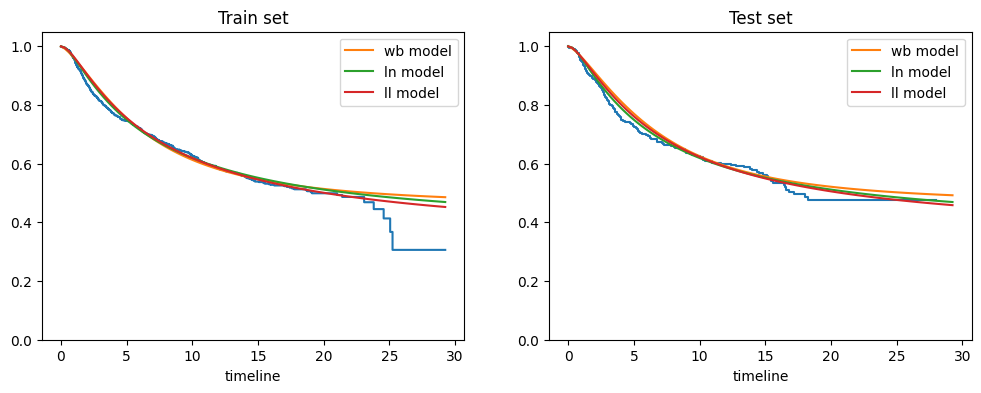

In [8]:
ts_grid = wb_summary["ts_grid"].flatten()

wb_S_ts_train = wb_summary["S_ts_train"]
wb_S_ts_train_avg = np.mean( wb_S_ts_train, axis = 1 )
ln_S_ts_train = ln_summary["S_ts_train"]
ln_S_ts_train_avg = np.mean( ln_S_ts_train, axis = 1 )
ll_S_ts_train = ll_summary["S_ts_train"]
ll_S_ts_train_avg = np.mean( ll_S_ts_train, axis = 1 )

wb_S_ts_test = wb_summary["S_ts_test"]
wb_S_ts_test_avg = np.mean( wb_S_ts_test, axis = 1 )
ln_S_ts_test = ln_summary["S_ts_test"]
ln_S_ts_test_avg = np.mean( ln_S_ts_train, axis = 1 )
ll_S_ts_test = ll_summary["S_ts_test"]
ll_S_ts_test_avg = np.mean( ll_S_ts_test, axis = 1 )

fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12,4))

km_train = lifelines.KaplanMeierFitter()
km_train.fit(y_train, delta_train)
km_train.plot(ax = ax[0], ci_show = False, show_censors = False, legend = False, label = '_')

# for j in range(500):
#     ax[0].plot(ts_grid, wb_S_ts_train[:,j], alpha = 0.05, color = "black")
ax[0].plot(ts_grid, wb_S_ts_train_avg, label = "wb model")
ax[0].plot(ts_grid, ln_S_ts_train_avg, label = "ln model")
ax[0].plot(ts_grid, ll_S_ts_train_avg, label = "ll model")
ax[0].set_ylim(0, 1.05)
ax[0].legend()
ax[0].set_title("Train set")

km_test = lifelines.KaplanMeierFitter()
km_test.fit(y_test, delta_test)
km_test.plot(ax = ax[1], ci_show = False, show_censors = False, legend = False, label = '_')
    
ax[1].plot(ts_grid, wb_S_ts_test_avg, label = "wb model")
ax[1].plot(ts_grid, ln_S_ts_test_avg, label = "ln model")
ax[1].plot(ts_grid, ll_S_ts_test_avg, label = "ll model")
ax[1].set_ylim(0, 1.05)
ax[1].legend()
ax[1].set_title("Test set")

plt.show()

In [9]:
pd.options.display.float_format = '{:.6f}'.format
mu_colnames = list( np.char.add("mu_", list(z_train_mu.columns)) )
sigma_colnames = list( np.char.add("sigma_", list(z_train_sigma.columns)) )
p_colnames = list( np.char.add("p_", list(z_train_p.columns)) )

colnames = mu_colnames + sigma_colnames + p_colnames

display( cure_aft.summary_betas(wb_model, colnames) )

pd.options.display.float_format = None

/home/natan/.pyenv/versions/3.10.17/lib/python3.10/site-packages/thetaflow/modelnn.py:2871: UserWarning: Model supports both neural network modeled parameters and independent parameters.
As a list of input values, x, was not provided, obtaining the covariances only for ['mu_beta', 'sigma_beta', 'p_beta'].
  warnings.warn(


,Coef,Se,Z,pvalue,CI(95%)
mu_age_at_diagnosis,-0.052640,0.046419,-1.134016,0.256788,(-0.1436 ; 0.0383)
mu_npi,-0.046506,0.044778,-1.038591,0.298995,(-0.1343 ; 0.0413)
mu_pam50_subtype_Basal,-0.620662,0.154616,-4.014208,0.000060,(-0.9237 ; -0.3176)
mu_pam50_subtype_Her2,-0.177040,0.142667,-1.240928,0.214632,(-0.4567 ; 0.1026)
mu_pam50_subtype_LumB,-0.040291,0.112269,-0.358883,0.719683,(-0.2603 ; 0.1798)
mu_pam50_subtype_Normal,0.115811,0.213617,0.542143,0.587720,(-0.3029 ; 0.5345)
mu_pam50_subtype_claudin-low,0.330728,0.350924,0.942449,0.345963,(-0.3571 ; 1.0185)
sigma_const,-0.543231,0.081811,-6.640055,0.000000,(-0.7036 ; -0.3829)
sigma_pam50_subtype_Basal,0.241006,0.135992,1.772210,0.076360,(-0.0255 ; 0.5075)
sigma_pam50_subtype_Her2,0.189197,0.149474,1.265752,0.205602,(-0.1038 ; 0.4822)


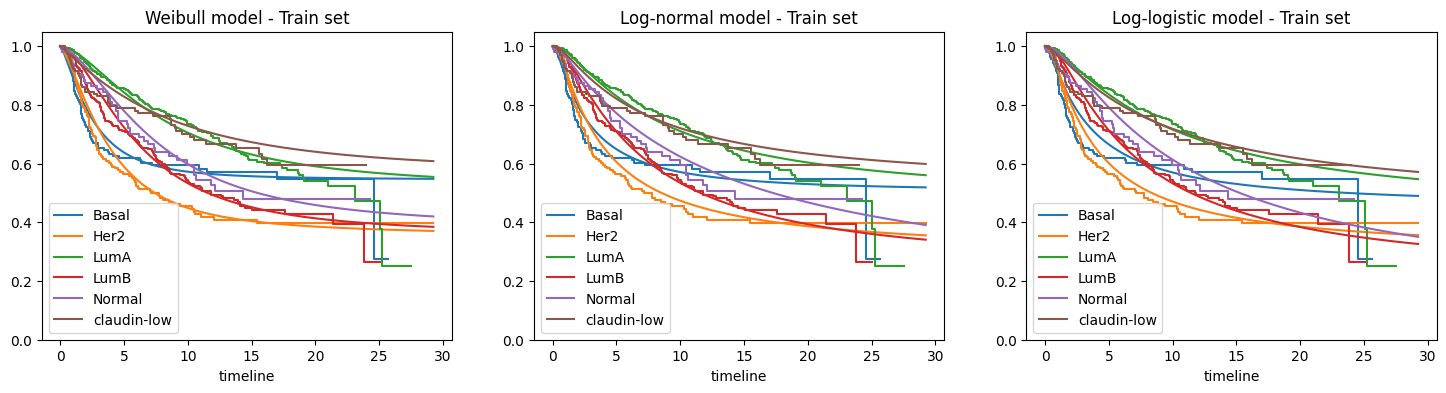

In [10]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18,4))

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
ts_grid = wb_summary["ts_grid"].flatten()
wb_S_ts_train = wb_summary["S_ts_train"]
ln_S_ts_train = ln_summary["S_ts_train"]
ll_S_ts_train = ll_summary["S_ts_train"]

unique_pam50_subtypes = np.sort( df_clean_train["pam50_subtype"].unique() )

for i, subtype in enumerate(unique_pam50_subtypes):
    subtype_patients = df_clean_train["pam50_subtype"] == subtype
    time = df_clean_train.loc[subtype_patients, "time"] / 12
    delta = df_clean_train.loc[subtype_patients, "delta"]

    wb_S_ts_train_subtype_avg = np.mean(wb_S_ts_train[:, subtype_patients], axis = 1)
    ln_S_ts_train_subtype_avg = np.mean(ln_S_ts_train[:, subtype_patients], axis = 1)
    ll_S_ts_train_subtype_avg = np.mean(ll_S_ts_train[:, subtype_patients], axis = 1)

    ax[0].plot(ts_grid, wb_S_ts_train_subtype_avg, color = colors[i])
    ax[1].plot(ts_grid, ln_S_ts_train_subtype_avg, color = colors[i])
    ax[2].plot(ts_grid, ll_S_ts_train_subtype_avg, color = colors[i])
    
    km = lifelines.KaplanMeierFitter()
    km.fit(time, delta)
    km.plot(ax = ax[0], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[2], ci_show = False, show_censors = False, label = subtype)

ax[0].set_title("Weibull model - Train set")
ax[0].set_ylim(0, 1.05)
ax[1].set_title("Log-normal model - Train set")
ax[1].set_ylim(0, 1.05)
ax[2].set_title("Log-logistic model - Train set")
ax[2].set_ylim(0, 1.05)

plt.show()

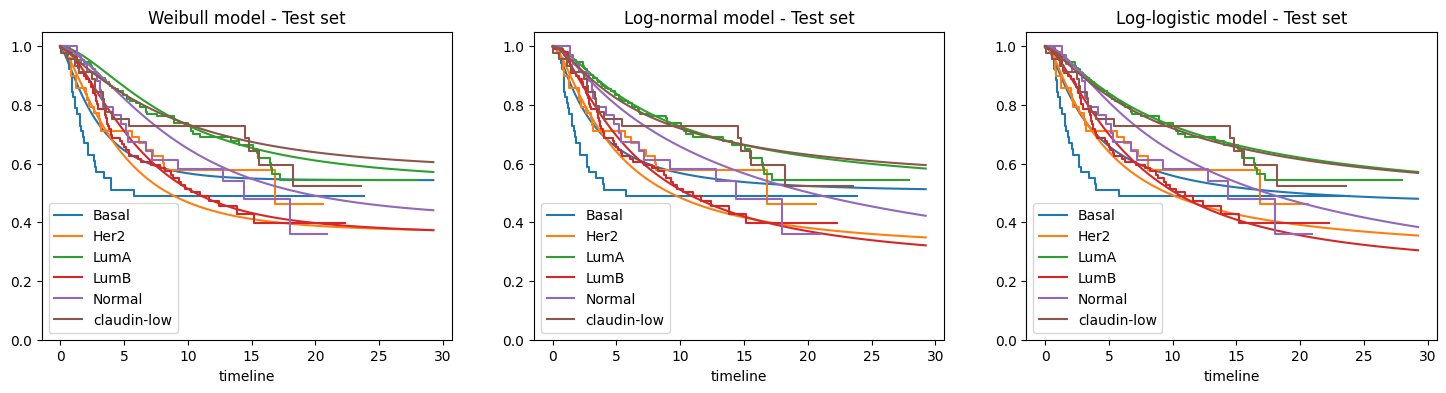

In [11]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18,4))

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
ts_grid = wb_summary["ts_grid"].flatten()
wb_S_ts_test = wb_summary["S_ts_test"]
ln_S_ts_test = ln_summary["S_ts_test"]
ll_S_ts_test = ll_summary["S_ts_test"]

unique_pam50_subtypes = np.sort( df_clean_train["pam50_subtype"].unique() )

for i, subtype in enumerate(unique_pam50_subtypes):
    subtype_patients = df_clean_test["pam50_subtype"] == subtype
    time = df_clean_test.loc[subtype_patients, "time"] / 12
    delta = df_clean_test.loc[subtype_patients, "delta"]

    wb_S_ts_test_subtype_avg = np.mean(wb_S_ts_test[:, subtype_patients], axis = 1)
    ln_S_ts_test_subtype_avg = np.mean(ln_S_ts_test[:, subtype_patients], axis = 1)
    ll_S_ts_test_subtype_avg = np.mean(ll_S_ts_test[:, subtype_patients], axis = 1)

    ax[0].plot(ts_grid, wb_S_ts_test_subtype_avg, color = colors[i])
    ax[1].plot(ts_grid, ln_S_ts_test_subtype_avg, color = colors[i])
    ax[2].plot(ts_grid, ll_S_ts_test_subtype_avg, color = colors[i])
    
    km = lifelines.KaplanMeierFitter()
    km.fit(time, delta)
    km.plot(ax = ax[0], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)
    km.plot(ax = ax[2], ci_show = False, show_censors = False, label = subtype)

ax[0].set_title("Weibull model - Test set")
ax[0].set_ylim(0, 1.05)
ax[1].set_title("Log-normal model - Test set")
ax[1].set_ylim(0, 1.05)
ax[2].set_title("Log-logistic model - Test set")
ax[2].set_ylim(0, 1.05)

plt.show()

In [12]:
wb_model.save_model("../model_weights/Classic Holdout/Structure2/wb_model")
ln_model.save_model("../model_weights/Classic Holdout/Structure2/ln_model")
ll_model.save_model("../model_weights/Classic Holdout/Structure2/ll_model")

Model successfully saved to ../model_weights/Classic Holdout/Structure2/wb_model.weights.h5 and ../model_weights/Classic Holdout/Structure2/wb_model_meta.pkl
Model successfully saved to ../model_weights/Classic Holdout/Structure2/ln_model.weights.h5 and ../model_weights/Classic Holdout/Structure2/ln_model_meta.pkl
Model successfully saved to ../model_weights/Classic Holdout/Structure2/ll_model.weights.h5 and ../model_weights/Classic Holdout/Structure2/ll_model_meta.pkl
